# Eksperimen Bayesian: Multinomial Naive Bayes

Tujuan: klasifikasi komentar promosi judi menggunakan **TF-IDF + MultinomialNB**. Dua eksperimen dibandingkan: data asli saja dan data asli dengan tambahan sintetis di bagian latihan.

Pembagian data asli: **60% train, 20% validation, 20% test**, stratified dan seed tetap. TF-IDF hanya di-fit pada bagian latihan setiap kandidat. Parameter dan pilihan eksperimen dipilih dari validation F1 kelas `1`. Setelah pilihan dikunci, model dilatih kembali pada train + validation; test asli dipakai untuk evaluasi akhir kedua eksperimen yang sudah ditetapkan.

`1` diperlakukan sebagai promosi judi dan `0` sebagai nonjudi sesuai dugaan pemetaan sebelumnya. Metode anotasi dan arti label belum dikonfirmasi dari sumber; skor mengukur kecocokan dengan label yang tersedia.

Dependensi: Python, pandas, numpy, scikit-learn, matplotlib, joblib; IPython opsional untuk tampilan tabel. Jalankan setelah notebook cleaning dan generator. File sumber tidak diubah. Sel ekspor terakhir menulis model, prediksi, grafik, dan ringkasan ke `outputs/bayesian/`.

Sumber dataset awal: [Judi Online — Kaggle](https://www.kaggle.com/datasets/yaemico/judionline), identifier `yaemico/judionline`, berdasarkan informasi anggota kelompok. Catatan sumber dan batas verifikasi tersedia di [dataset/README.md](dataset/README.md). Komentar sintetis dibuat terpisah oleh kelompok, bukan diperoleh dari Kaggle.


## 1. Konfigurasi dan dependensi

Grid kecil mencoba kata unigram/bigram dan karakter 3–5 gram. Representasi karakter dapat menangkap bagian nama dan variasi tulisan; hasil terbaik tidak diasumsikan sebelumnya. `alpha` adalah smoothing untuk mengurangi masalah fitur yang jarang muncul. MultinomialNB menerima fitur nonnegatif; TF-IDF digunakan di sini sebagai baseline teks.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform
import re
import unicodedata
import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string() if isinstance(value, (pd.DataFrame, pd.Series)) else value)

SEED = 42
TEST_SIZE = 0.20
VALIDATION_SIZE = 0.20
ALPHAS = [0.1, 0.5, 1.0]
FEATURES = {
    'word_1_2': {'analyzer': 'word', 'ngram_range': (1, 2)},
    'char_wb_3_5': {'analyzer': 'char_wb', 'ngram_range': (3, 5)},
}
MAX_FEATURES = 40_000
LABEL_NAMES = ['0: nonjudi (asumsi)', '1: promosi judi (asumsi)']
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / 'dataset').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
CLEAN_PATH = PROJECT_DIR / 'outputs/cleaning/komentar_cleaned.csv'
AUGMENT_PATH = PROJECT_DIR / 'outputs/augmentation/komentar_10000_with_synthetic.csv'
OUT_DIR = PROJECT_DIR / 'outputs/bayesian'
pd.set_option('display.max_colwidth', 120)
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

Python: 3.14.3 | scikit-learn: 1.8.0


## 2. Muat data dan periksa asalnya

Kolom penanda asal harus dibaca eksplisit; string `False` tidak boleh diubah dengan `astype(bool)` karena dapat dianggap benar. Metadata, ID, dan `is_synthetic` tidak menjadi fitur. Isi komentar hasil cleaning adalah satu-satunya input model.

In [2]:
for path in [CLEAN_PATH, AUGMENT_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f'{path} belum tersedia. Jalankan notebook sebelumnya.')
source_hashes = {path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in [CLEAN_PATH, AUGMENT_PATH]}
original = pd.read_csv(CLEAN_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
combined = pd.read_csv(AUGMENT_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
for frame in [original, combined]:
    assert {'source_row', 'komentar', 'komentar_processed', 'label'}.issubset(frame.columns)
    assert frame['label'].isin(['0', '1']).all()
    frame['label'] = frame['label'].astype(int)
    assert not frame['komentar_processed'].str.strip().eq('').any()
    assert not frame['komentar_processed'].duplicated().any()
assert {'is_synthetic', 'data_origin', 'synthetic_id'}.issubset(combined.columns)
flag = combined['is_synthetic'].str.lower().map({'true': True, 'false': False})
assert flag.notna().all(), 'Penanda sintetis tidak valid.'
synthetic = combined.loc[flag].copy().reset_index(drop=True)
combined_original = combined.loc[~flag].copy()
assert len(synthetic) > 0 and synthetic['label'].eq(1).all()
assert synthetic['data_origin'].eq('synthetic_template').all()
assert combined_original['data_origin'].eq('source_dataset').all()
assert original['source_row'].is_unique and synthetic['synthetic_id'].is_unique
check_cols = ['source_row', 'komentar', 'komentar_processed', 'label']
pd.testing.assert_frame_equal(original[check_cols].sort_values('source_row').reset_index(drop=True),
                              combined_original[check_cols].sort_values('source_row').reset_index(drop=True))
assert set(original['komentar_processed']).isdisjoint(synthetic['komentar_processed'])
assert len(original) + len(synthetic) == len(combined)
print(f'Asli: {len(original):,}; sintetis: {len(synthetic):,}; gabungan: {len(combined):,}')
display(pd.crosstab(combined['data_origin'], combined['label']))

Asli: 8,934; sintetis: 1,066; gabungan: 10,000
label                  0     1
data_origin                   
source_dataset      6016  2918
synthetic_template     0  1066


## 3. Pembagian train, validation, dan test asli

Deduplikasi teks sudah dilakukan sebelumnya. Split ini acak pada teks unik, **bukan pemisahan video/channel atau template**. Komentar mirip dan nama situs yang sama masih mungkin ada di bagian berbeda, sehingga skor belum menunjukkan generalisasi ke video, kampanye, atau situs baru. Manifest ID diekspor agar ANN dan SVM nanti dapat memakai pembagian yang sama.

In [3]:
assert 0 < TEST_SIZE < 1 and 0 < VALIDATION_SIZE < 1 - TEST_SIZE
trainval, test = train_test_split(original, test_size=TEST_SIZE, stratify=original['label'], random_state=SEED)
train, validation = train_test_split(trainval, test_size=VALIDATION_SIZE / (1 - TEST_SIZE),
                                   stratify=trainval['label'], random_state=SEED)
train, validation, test = [part.reset_index(drop=True) for part in [train, validation, test]]
parts = {'train': train, 'validation': validation, 'test': test}
for name, part in parts.items():
    assert set(part['label']) == {0, 1}, f'{name} harus memuat kedua kelas.'
for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(parts[left]['source_row']).isdisjoint(parts[right]['source_row'])
    assert set(parts[left]['komentar_processed']).isdisjoint(parts[right]['komentar_processed'])
assert sum(map(len, parts.values())) == len(original)
manifest = pd.concat([part[['source_row']].assign(split=name) for name, part in parts.items()], ignore_index=True)
assert manifest['source_row'].is_unique
split_counts = pd.DataFrame({name: part['label'].value_counts() for name, part in parts.items()}).T.fillna(0).astype(int)
split_counts['total'] = split_counts.sum(axis=1)
display(split_counts)
print('Tambahan sintetis hanya pada train:', len(synthetic))

label          0     1  total
train       3610  1750   5360
validation  1203   584   1787
test        1203   584   1787
Tambahan sintetis hanya pada train: 1066


## 4. Pipeline dan metrik

Kedua eksperimen memakai grid kandidat identik dan validation asli yang sama. Pipeline memastikan kosakata serta IDF dipelajari ulang hanya dari data latihan masing-masing kandidat. Tidak ada tuning threshold: prediksi memakai keputusan default model. F1 kelas positif (`1`) adalah metrik pemilihan utama; macro-F1 menjadi pemecah seri.

In [4]:
def make_pipeline(feature_name, alpha):
    return Pipeline([
        ('tfidf', TfidfVectorizer(**FEATURES[feature_name], lowercase=False, min_df=2,
                                  max_features=MAX_FEATURES, sublinear_tf=True)),
        ('nb', MultinomialNB(alpha=alpha)),
    ])

def metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision_1': float(precision_score(y_true, y_pred, zero_division=0)),
        'recall_1': float(recall_score(y_true, y_pred, zero_division=0)),
        'f1_1': float(f1_score(y_true, y_pred, zero_division=0)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
    }

training_sets = {
    'original_only': train,
    'with_synthetic': pd.concat([train, synthetic[train.columns]], ignore_index=True),
}

## 5. Training kandidat dan seleksi lewat validation

Jumlah kandidat: 2 representasi × 3 nilai alpha × 2 skenario = 12 proses latihan. Skor test belum dihitung di tahap ini. Waktu yang dicatat meliputi fit TF-IDF dan classifier, bukan pembacaan data atau prediksi validation.

In [5]:
tuning_records = []
for arm, fit_data in training_sets.items():
    for feature_name in FEATURES:
        for alpha in ALPHAS:
            candidate = make_pipeline(feature_name, alpha)
            start = perf_counter()
            candidate.fit(fit_data['komentar_processed'], fit_data['label'])
            fit_seconds = perf_counter() - start
            pred = candidate.predict(validation['komentar_processed'])
            tuning_records.append({
                'experiment': arm, 'features': feature_name, 'alpha': alpha,
                'fit_rows': len(fit_data), 'fit_seconds': fit_seconds,
                **metrics(validation['label'], pred),
            })
tuning_results = pd.DataFrame(tuning_records)
ranked = tuning_results.sort_values(['f1_1', 'macro_f1', 'experiment', 'features', 'alpha'],
                                   ascending=[False, False, True, True, True], kind='stable')
best_per_arm = ranked.groupby('experiment', sort=False).head(1).reset_index(drop=True)
selected_arm = str(ranked.iloc[0]['experiment'])
selected_config = ranked.iloc[0][['experiment', 'features', 'alpha']].to_dict()
display(ranked.round(4))
print('Konfigurasi terbaik per eksperimen:')
display(best_per_arm.round(4))
print('Pilihan berdasarkan validation saja:', selected_config)

        experiment     features  alpha  fit_rows  fit_seconds  accuracy  precision_1  recall_1    f1_1  macro_f1
3    original_only  char_wb_3_5    0.1      5360       0.4012    0.9782       0.9595    0.9743  0.9669    0.9753
4    original_only  char_wb_3_5    0.5      5360       0.3624    0.9782       0.9674    0.9658  0.9666    0.9752
5    original_only  char_wb_3_5    1.0      5360       0.4490    0.9782       0.9789    0.9538  0.9662    0.9750
9   with_synthetic  char_wb_3_5    0.1      6426       0.5169    0.9642       0.9392    0.9521  0.9456    0.9594
1    original_only     word_1_2    0.5      5360       0.0981    0.9619       0.9657    0.9161  0.9402    0.9562
0    original_only     word_1_2    0.1      5360       0.1057    0.9614       0.9541    0.9264  0.9401    0.9558
10  with_synthetic  char_wb_3_5    0.5      6426       0.4834    0.9569       0.9190    0.9521  0.9352    0.9515
2    original_only     word_1_2    1.0      5360       0.1006    0.9564       0.9720    0.8921  

## 6. Refit konfigurasi yang sudah dipilih

Latih ulang tiap konfigurasi terbaik memakai seluruh data development asli (train + validation). Untuk skenario augmentasi, tambahkan sintetis yang sama. Pilihan eksperimen sudah dikunci sebelum test. Model yang disimpan tetap tidak dilatih pada test supaya evaluasinya sesuai artefak model.

In [6]:
development = pd.concat([train, validation], ignore_index=True)
final_models, fit_times = {}, {}
for row in best_per_arm.itertuples(index=False):
    fit_data = development if row.experiment == 'original_only' else pd.concat([development, synthetic[development.columns]], ignore_index=True)
    model = make_pipeline(row.features, float(row.alpha))
    start = perf_counter()
    model.fit(fit_data['komentar_processed'], fit_data['label'])
    fit_times[row.experiment] = perf_counter() - start
    final_models[row.experiment] = model
selected_model = final_models[selected_arm]
print('Refit selesai; test belum digunakan untuk fit atau pemilihan parameter.')

Refit selesai; test belum digunakan untuk fit atau pemilihan parameter.


## 7. Evaluasi akhir pada test asli

Kedua skenario yang telah ditetapkan diuji pada test yang sama. Jangan mengganti parameter atau memilih ulang skenario berdasarkan tabel test ini. Baseline mayoritas membantu melihat apakah model melampaui tebakan kelas paling banyak; model ini juga hanya belajar dari data development.

In [7]:
test_records, predictions, reports, matrices = [], {}, {}, {}
for arm, model in final_models.items():
    start = perf_counter()
    pred = model.predict(test['komentar_processed'])
    prediction_seconds = perf_counter() - start
    predictions[arm] = pred
    test_records.append({'experiment': arm, **metrics(test['label'], pred),
                         'refit_seconds': fit_times[arm], 'test_predict_seconds': prediction_seconds})
    reports[arm] = classification_report(test['label'], pred, labels=[0, 1], target_names=LABEL_NAMES,
                                       output_dict=True, zero_division=0)
    matrices[arm] = confusion_matrix(test['label'], pred, labels=[0, 1])
    print(arm)
    display(pd.DataFrame(reports[arm]).T.round(4))
dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(development), 1)), development['label'])
dummy_pred = dummy.predict(np.zeros((len(test), 1)))
test_records.append({'experiment': 'majority_baseline', **metrics(test['label'], dummy_pred),
                     'refit_seconds': None, 'test_predict_seconds': None})
test_results = pd.DataFrame(test_records)
display(test_results.round(4))
print('Pilihan tetap berdasarkan validation:', selected_arm)

original_only
                          precision  recall  f1-score    support
0: nonjudi (asumsi)          0.9907  0.9776    0.9841  1203.0000
1: promosi judi (asumsi)     0.9550  0.9812    0.9679   584.0000
accuracy                     0.9787  0.9787    0.9787     0.9787
macro avg                    0.9729  0.9794    0.9760  1787.0000
weighted avg                 0.9791  0.9787    0.9788  1787.0000
with_synthetic
                          precision  recall  f1-score    support
0: nonjudi (asumsi)          0.9823  0.9701    0.9762  1203.0000
1: promosi judi (asumsi)     0.9399  0.9640    0.9518   584.0000
accuracy                     0.9681  0.9681    0.9681     0.9681
macro avg                    0.9611  0.9671    0.9640  1787.0000
weighted avg                 0.9685  0.9681    0.9682  1787.0000
          experiment  accuracy  precision_1  recall_1    f1_1  macro_f1  refit_seconds  test_predict_seconds
0      original_only    0.9787       0.9550    0.9812  0.9679    0.9760         0.

## 8. Confusion matrix dan perbandingan metrik

Baris confusion matrix menunjukkan label rujukan; kolom menunjukkan prediksi. False positive = komentar berlabel `0` diprediksi `1`; false negative = komentar berlabel `1` diprediksi `0`. Skor disimpan pada skala 0–1.

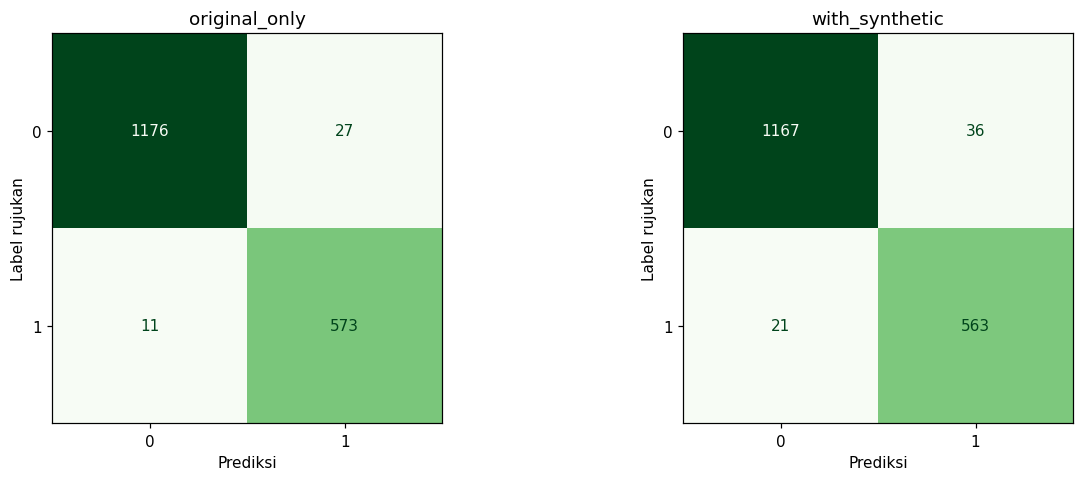

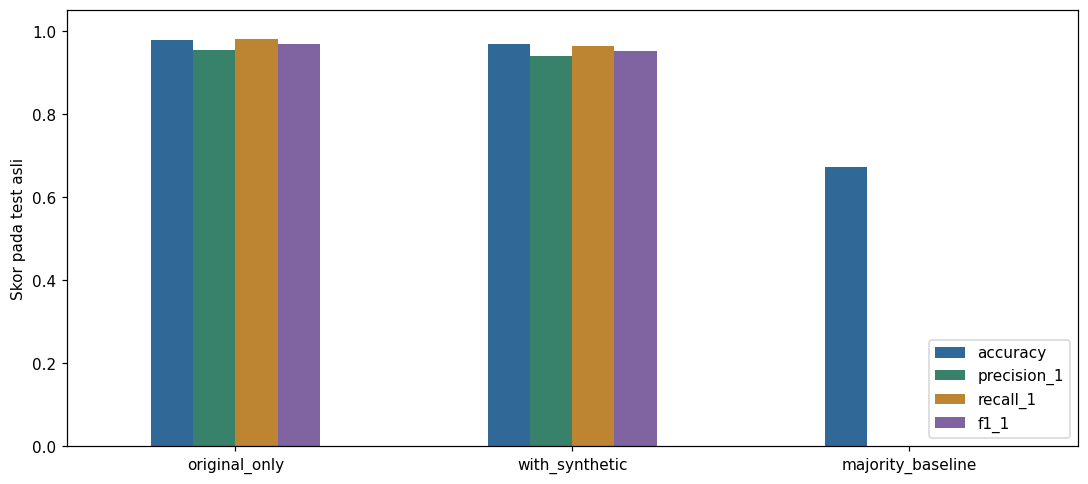

In [8]:
fig_cm, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (arm, matrix) in zip(axes, matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=['0', '1']).plot(ax=ax, colorbar=False, cmap='Greens')
    ax.set_title(arm)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Label rujukan')
fig_cm.tight_layout()
plt.show()
fig_metrics, ax = plt.subplots(figsize=(10, 4.5))
test_results.set_index('experiment')[['accuracy', 'precision_1', 'recall_1', 'f1_1']].plot.bar(ax=ax, color=['#306998', '#38816b', '#bd8432', '#8064a2'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Skor pada test asli')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=0)
ax.legend(loc='lower right')
fig_metrics.tight_layout()
plt.show()

## 9. Analisis kesalahan dan fitur

Contoh kesalahan adalah bahan pembahasan, bukan alasan untuk mengubah model setelah melihat test. Periksa kembali juga label rujukannya. Rasio log probabilitas fitur membantu menunjukkan kecenderungan model, bukan penjelasan sebab-akibat.

In [9]:
test_predictions = test[['source_row', 'komentar', 'komentar_processed', 'label']].copy()
for arm, model in final_models.items():
    test_predictions[f'pred_{arm}'] = predictions[arm]
    test_predictions[f'prob_1_{arm}'] = model.predict_proba(test['komentar_processed'])[:, list(model.named_steps['nb'].classes_).index(1)]
selected_predictions = predictions[selected_arm]
errors = test_predictions.loc[test['label'].ne(selected_predictions)].copy()
errors['error_type'] = np.where(errors['label'].eq(0), 'false_positive', 'false_negative')
print('Jumlah kesalahan model pilihan:', len(errors))
for error_type in ['false_positive', 'false_negative']:
    print(error_type)
    display(errors.loc[errors['error_type'].eq(error_type), ['komentar', 'label', f'pred_{selected_arm}', f'prob_1_{selected_arm}']].head(8))
nb = selected_model.named_steps['nb']
terms = selected_model.named_steps['tfidf'].get_feature_names_out()
classes = list(nb.classes_)
log_ratio = nb.feature_log_prob_[classes.index(1)] - nb.feature_log_prob_[classes.index(0)]
feature_weights = pd.DataFrame({'fitur': terms, 'log_ratio_1_vs_0': log_ratio})
print('Fitur paling cenderung kelas 1:')
display(feature_weights.nlargest(15, 'log_ratio_1_vs_0').round(3))

Jumlah kesalahan model pilihan: 38
false_positive
                      komentar  label  pred_original_only  prob_1_original_only
119      Cuma buat bikin kesel      0                   1              0.678486
194                Terimakasih      0                   1              0.839044
205        taunya db9 game nfs      0                   1              0.910950
241                 Maksih bre      0                   1              0.935898
256   Org baru d pake, MANTAP!      0                   1              0.513587
325               mantep bener      0                   1              0.952845
405                 Pasti seru      0                   1              0.687603
501  keren banget, sukses 👍🙌🙌🙌      0                   1              0.960227
false_negative
                                                               komentar  label  pred_original_only  prob_1_original_only
262                      wadidaw kren bgt yak depo 50 doan jd 2jt wwk💫💫      1                

## 10. Coba komentar baru

Model tersimpan menerima **teks yang sudah dibersihkan**, sehingga komentar mentah diproses dulu dengan aturan yang sama. Contoh buatan di bawah hanya demonstrasi pemakaian, tidak masuk perhitungan skor. Probabilitas Naive Bayes belum dikalibrasi; jangan menganggapnya kepastian kebenaran.

In [10]:
url_pattern = re.compile(r'(?:https?://|www\.)[^\s<>]+', re.IGNORECASE)
def clean_comment(text):
    text = unicodedata.normalize('NFKC', text)
    text = ''.join('' if unicodedata.category(c) == 'Cf' else c for c in text)
    text = ''.join(' ' if unicodedata.category(c) == 'Cc' else c for c in text)
    text = url_pattern.sub('<url>', text.lower())
    return re.sub(r'\s+', ' ', text).strip()

new_comments = [
    'Videonya seru bang, ditunggu review mobil selanjutnya',
    'depo receh di SITUSDEMO88 malah dapet scatter, wd lancar 🔥',
    'Tolong hapus spam judi di kolom komentar ini',
    'Makasih penjelasannya, jadi ngerti cara merawat mesin',
]
demo = pd.DataFrame({'komentar': new_comments})
demo['komentar_processed'] = demo['komentar'].map(clean_comment)
demo['prediksi'] = selected_model.predict(demo['komentar_processed'])
demo['prob_1_belum_dikalibrasi'] = selected_model.predict_proba(demo['komentar_processed'])[:, list(nb.classes_).index(1)]
display(demo)

                                                     komentar                                          komentar_processed  prediksi  prob_1_belum_dikalibrasi
0       Videonya seru bang, ditunggu review mobil selanjutnya       videonya seru bang, ditunggu review mobil selanjutnya         0                  0.000010
1  depo receh di SITUSDEMO88 malah dapet scatter, wd lancar 🔥  depo receh di situsdemo88 malah dapet scatter, wd lancar 🔥         1                  0.999997
2                Tolong hapus spam judi di kolom komentar ini                tolong hapus spam judi di kolom komentar ini         0                  0.000965
3       Makasih penjelasannya, jadi ngerti cara merawat mesin       makasih penjelasannya, jadi ngerti cara merawat mesin         0                  0.012810


## 11. Simpan hasil dan verifikasi

Simpan kedua pipeline, hasil tuning, skor test, manifest split asli, prediksi test, kesalahan model pilihan, bobot fitur, dua gambar, dan ringkasan konfigurasi. Model joblib hanya boleh dimuat dari file tepercaya. File model mengharapkan `komentar_processed`; gunakan fungsi cleaning di atas untuk masukan mentah.

In [11]:
for path in [CLEAN_PATH, AUGMENT_PATH]:
    assert hashlib.sha256(path.read_bytes()).hexdigest() == source_hashes[path.name], 'Input berubah saat eksekusi.'
assert len(test_predictions) == len(test) and len(manifest) == len(original)
for arm, matrix in matrices.items():
    assert int(matrix.sum()) == len(test)
    assert len(predictions[arm]) == len(test)
    assert set(final_models[arm].named_steps['nb'].classes_) == {0, 1}
assert selected_arm in final_models
OUT_DIR.mkdir(parents=True, exist_ok=True)
tuning_results.to_csv(OUT_DIR / 'validation_results.csv', index=False)
test_results.to_csv(OUT_DIR / 'test_metrics.csv', index=False)
manifest.to_csv(OUT_DIR / 'original_split_manifest.csv', index=False)
test_predictions.to_csv(OUT_DIR / 'test_predictions.csv', index=False, encoding='utf-8-sig')
errors.to_csv(OUT_DIR / 'selected_model_errors.csv', index=False, encoding='utf-8-sig')
feature_weights.to_csv(OUT_DIR / 'selected_model_feature_weights.csv', index=False, encoding='utf-8-sig')
fig_cm.savefig(OUT_DIR / 'confusion_matrices.png', dpi=150, bbox_inches='tight')
fig_metrics.savefig(OUT_DIR / 'test_metrics.png', dpi=150, bbox_inches='tight')
for arm, model in final_models.items():
    path = OUT_DIR / f'naive_bayes_{arm}.joblib'
    joblib.dump(model, path)
    restored = joblib.load(path)
    assert np.array_equal(restored.predict(test['komentar_processed']), predictions[arm])
summary = {
    'algorithm': 'MultinomialNB', 'selection_metric': 'validation positive-class F1, then macro-F1',
    'seed': SEED, 'split_fractions': {'train': 1-TEST_SIZE-VALIDATION_SIZE, 'validation': VALIDATION_SIZE, 'test': TEST_SIZE},
    'original_rows': len(original), 'synthetic_train_rows': len(synthetic),
    'split_counts': {name: len(part) for name, part in parts.items()},
    'selected_experiment_before_test': selected_arm,
    'best_validation_per_experiment': best_per_arm.to_dict(orient='records'),
    'test_metrics': test_results.astype(object).where(test_results.notna(), None).to_dict(orient='records'),
    'classification_reports': reports,
    'confusion_matrices': {arm: matrix.tolist() for arm, matrix in matrices.items()},
    'source_sha256': source_hashes,
    'versions': {'python': platform.python_version(), 'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'joblib': joblib.__version__},
    'model_input': 'komentar_processed; preprocessing is provided in notebook, not embedded in joblib',
    'limitations': ['label meaning and annotation process unconfirmed', 'random text split, not video/campaign holdout', 'near-duplicate templates may span splits', 'synthetic template shortcuts', 'test has not been used to select parameters; avoid iterative tuning against test'],
}
(OUT_DIR / 'experiment_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
assert len(pd.read_csv(OUT_DIR / 'original_split_manifest.csv')) == len(original)
assert len(pd.read_csv(OUT_DIR / 'test_predictions.csv')) == len(test)
print('Ekspor dan pemeriksaan model hasil muat ulang berhasil.')
print('Output:', OUT_DIR.relative_to(PROJECT_DIR))

Ekspor dan pemeriksaan model hasil muat ulang berhasil.
Output: outputs\bayesian


## 12. Cara membaca hasil untuk paper

Laporkan konfigurasi terbaik menurut validation, jumlah data asli/sintetis, pembagian data, serta precision, recall, F1 kelas positif, macro-F1, accuracy, dan confusion matrix pada test asli. Bandingkan dua eksperimen tanpa menyembunyikan jika augmentasi menurunkan skor. Hindari klaim akurasi pada seluruh YouTube: test berasal dari sumber terbatas dan pembagian acak teks unik.

Pakai `original_split_manifest.csv` yang sama saat membandingkan ANN dan SVM. Untuk penelitian lanjutan, validasi ulang anotasi dan gunakan evaluasi video/kampanye terpisah sebelum menyimpulkan kemampuan generalisasi.

Referensi implementasi: [MultinomialNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html), [TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).